<a href="https://colab.research.google.com/github/gyeongee/TIL/blob/main/%EB%A1%9C%EC%A7%80%EC%8A%A4%ED%8B%B1%ED%9A%8C%EA%B7%80.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

선형 계층 함수 직후에 시그모이드 함수를 넣어주어 전체 모델을 구성합니다.

## 기본 개념
- 데이터가 어떤 범주에 속할 확률을 0과 1사이의 값으로 정하고 그 확률에 따라 가능성이 더 높은 범주에 속하는지 분류하는 알고리즘 (<font color=orange>이진 분류 (Binary Classfication)</font>)
- <font color=orange>시그모이드(Sigmoid)</font> 함수 : 로지스틱 함수의 종류로 기준값보다 작으면 0, 크면 1로 이진화하는 함수

<center>  
<img src="https://arome1004.cafe24.com/images/pytorch/lecture_image/04_sigmoid.png" width=40%>   
</center>  

- <font color=orange>활성화(Activation)</font> 함수
  - 인공신경망에서 입력 신호의 가중치 합을 출력 신호로 변환하는 함수
  - <font color=orange>비선형성(non-linearity)</font>을 가지고 있으며, 입력에 대한 비선형 변환을 통해 신경망이 다양한 종류의 <font color=orange>복잡한 함수를 학습</font>할 수 있게 함
  - 종류 : Sigmoid, tanh, ReLU 등

## 로지스틱 회귀 모델 학습 과정
- 데이터 셋 D : N개의 n차원 입력벡터와 N개의 m차원 출력벡터로 구성
랜덤으로 파라미터(w, b)를 초기화
- n 차원의 입력벡터를 선형회귀 모델 통과시키면 (Feed-foreward) m 차원의 출력벡터를 얻음
- <font color=orange>얻은 출력벡터는 시그모이드 함수를 통해 비선형 변환을 수행하여 최종 출력벡터를 얻음</font>
- 입력벡터와 출력벡터를 비교하여 손실값을 계산
- <font color=orange>시그모이드 함수를 미분하여 손실값에 곱해서 신경망 노드로 전달</font>
- 전달받은 손실값을 각 파라미터(w, b)로 미분한 값으로 파라미터를 업데이트 (학습률 적용)
- global minimum이 되거나 목표 손실값 이하가 될때까지 반복



<center>  
<img src="https://arome1004.cafe24.com/images/pytorch/lecture_image/04_logistic_regression.png" width=60%>   
</center>


로지스틱 회귀와 같은 이진 분류 문제를 풀기 위해서는 이진 크로스엔트로피(binary cross-entropy,BCE) 손실함수를 사용합니다.

In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [39]:
import torch
import torch.nn as nn
import torch.nn.functional as F

import torch.optim as optim
from tqdm import tqdm

In [59]:
from sklearn.datasets import load_breast_cancer
cancer=load_breast_cancer()

df=pd.DataFrame(data=cancer.data,columns=cancer.feature_names)
df['target']=cancer.target
df.head(3)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0


In [41]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

시각화

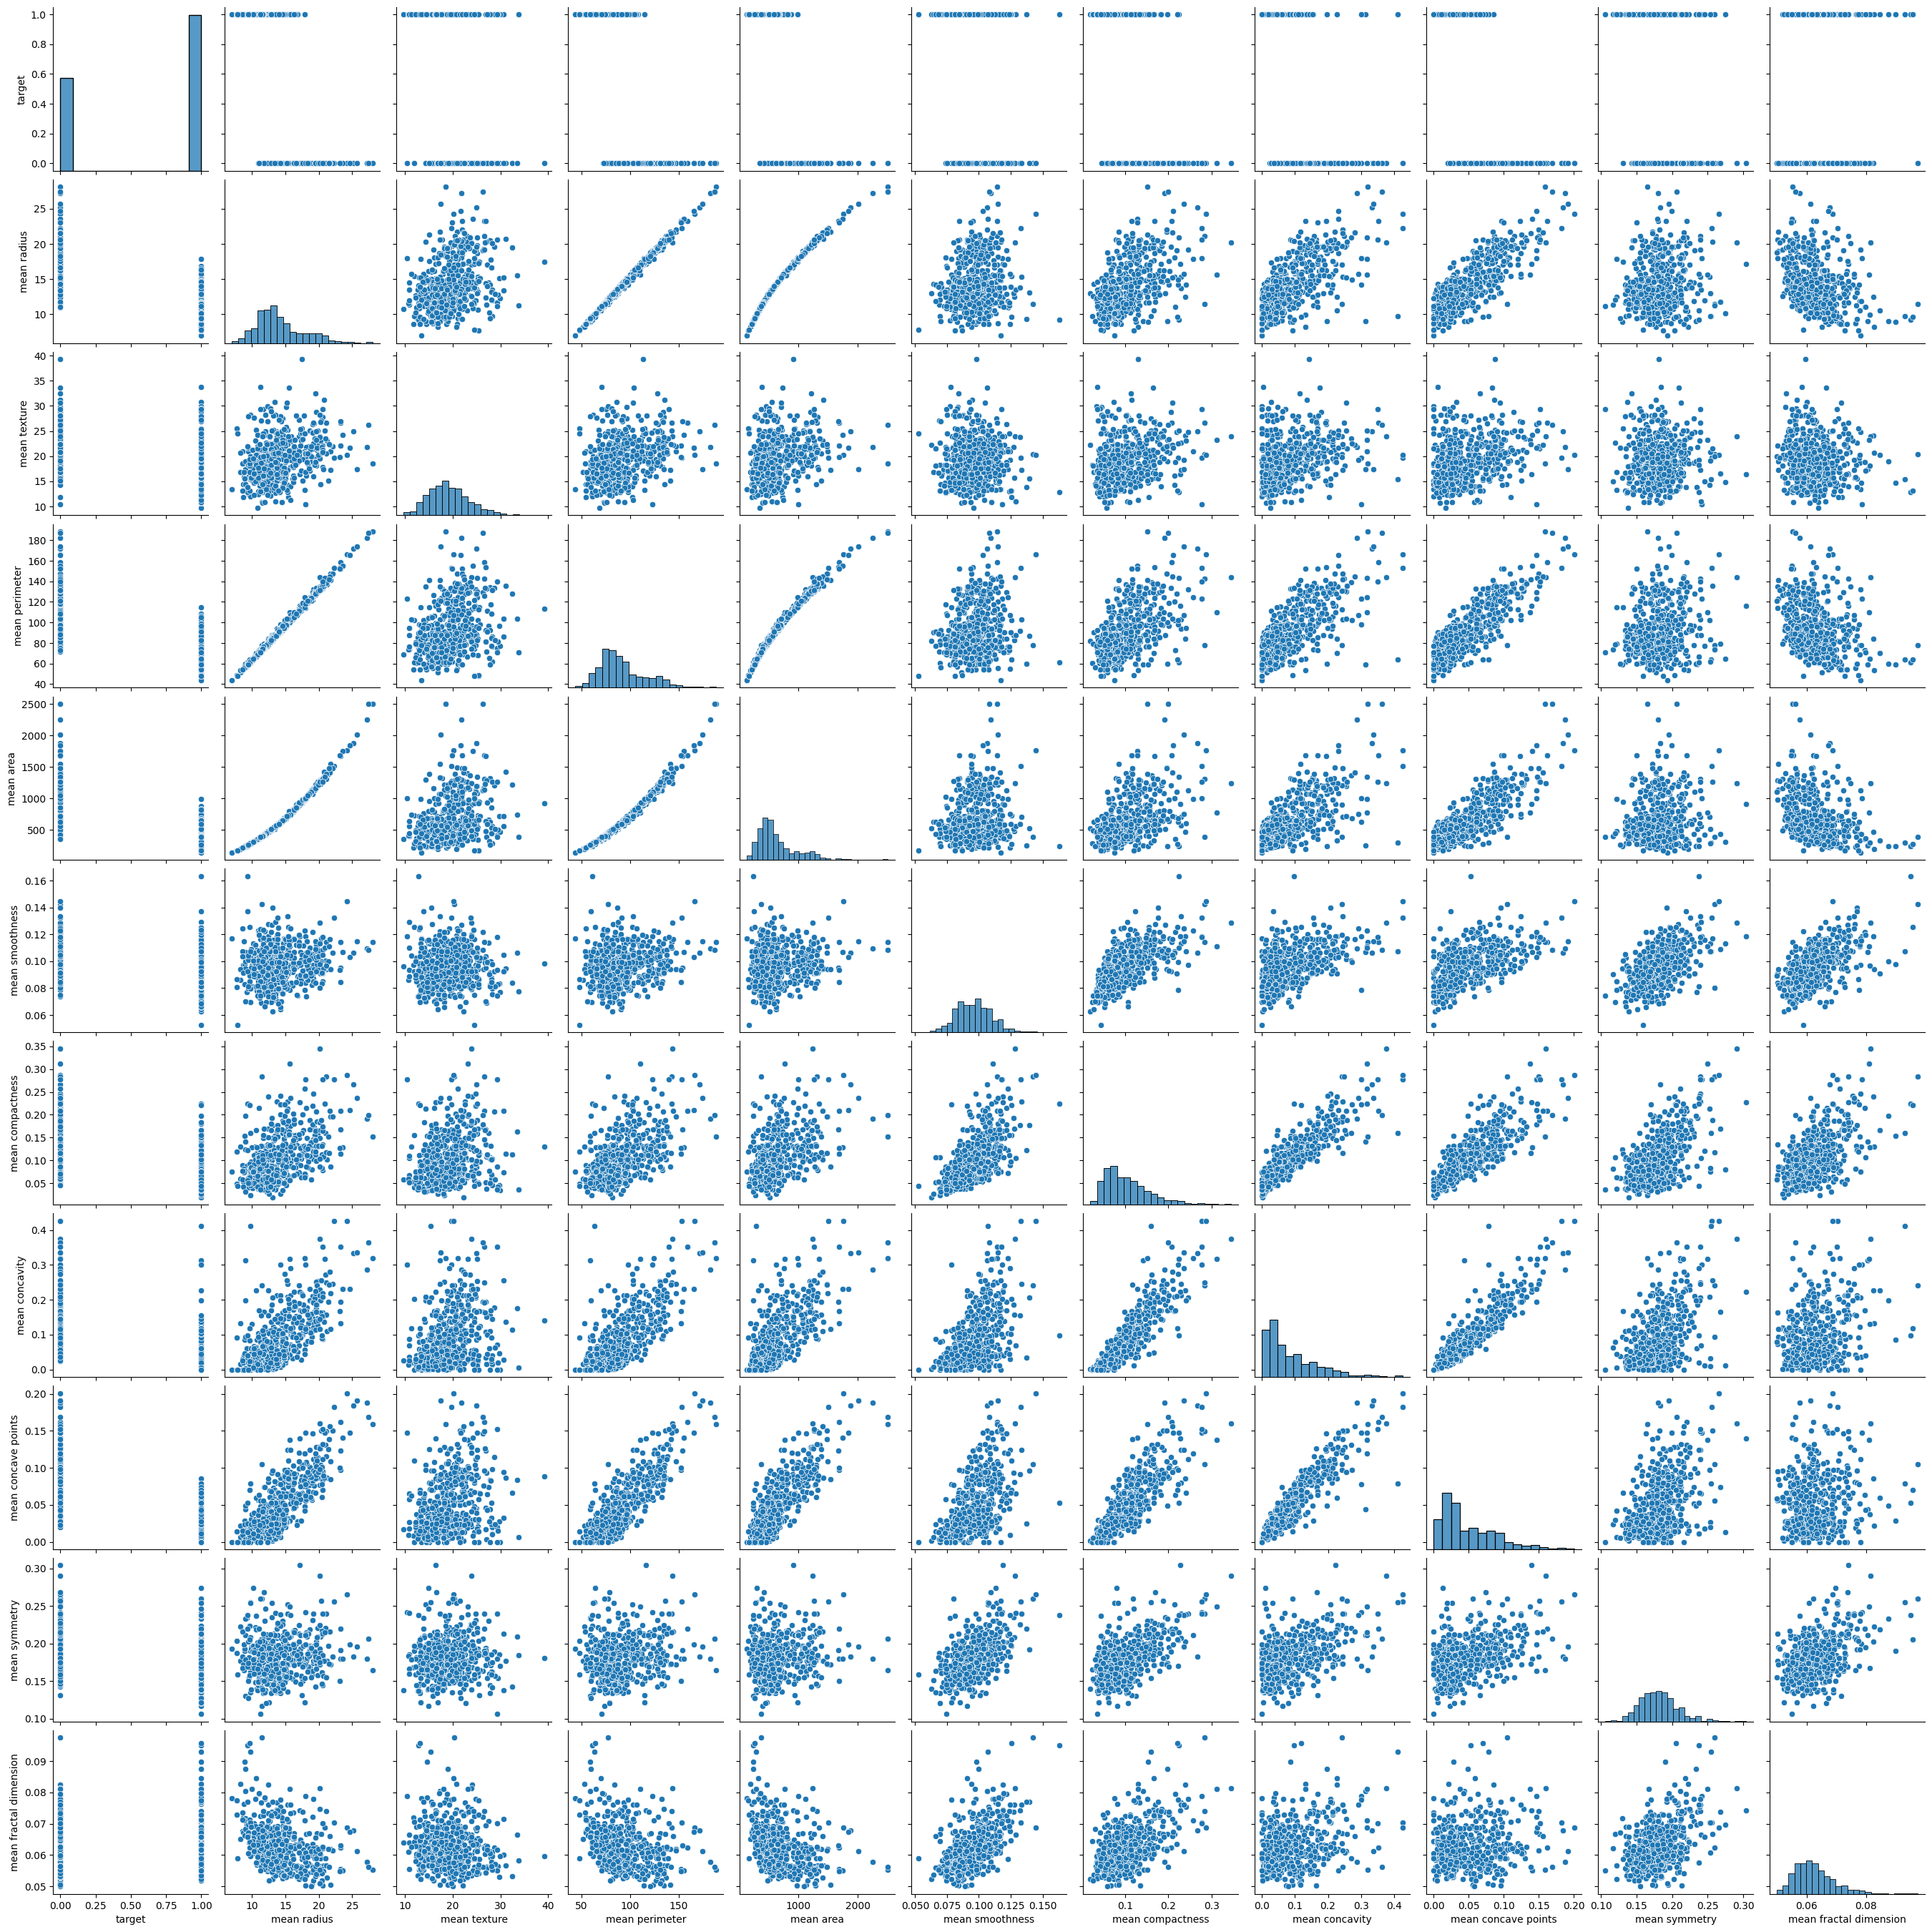

In [42]:
sns.pairplot(df[['target'] + list(df.columns[:10])])

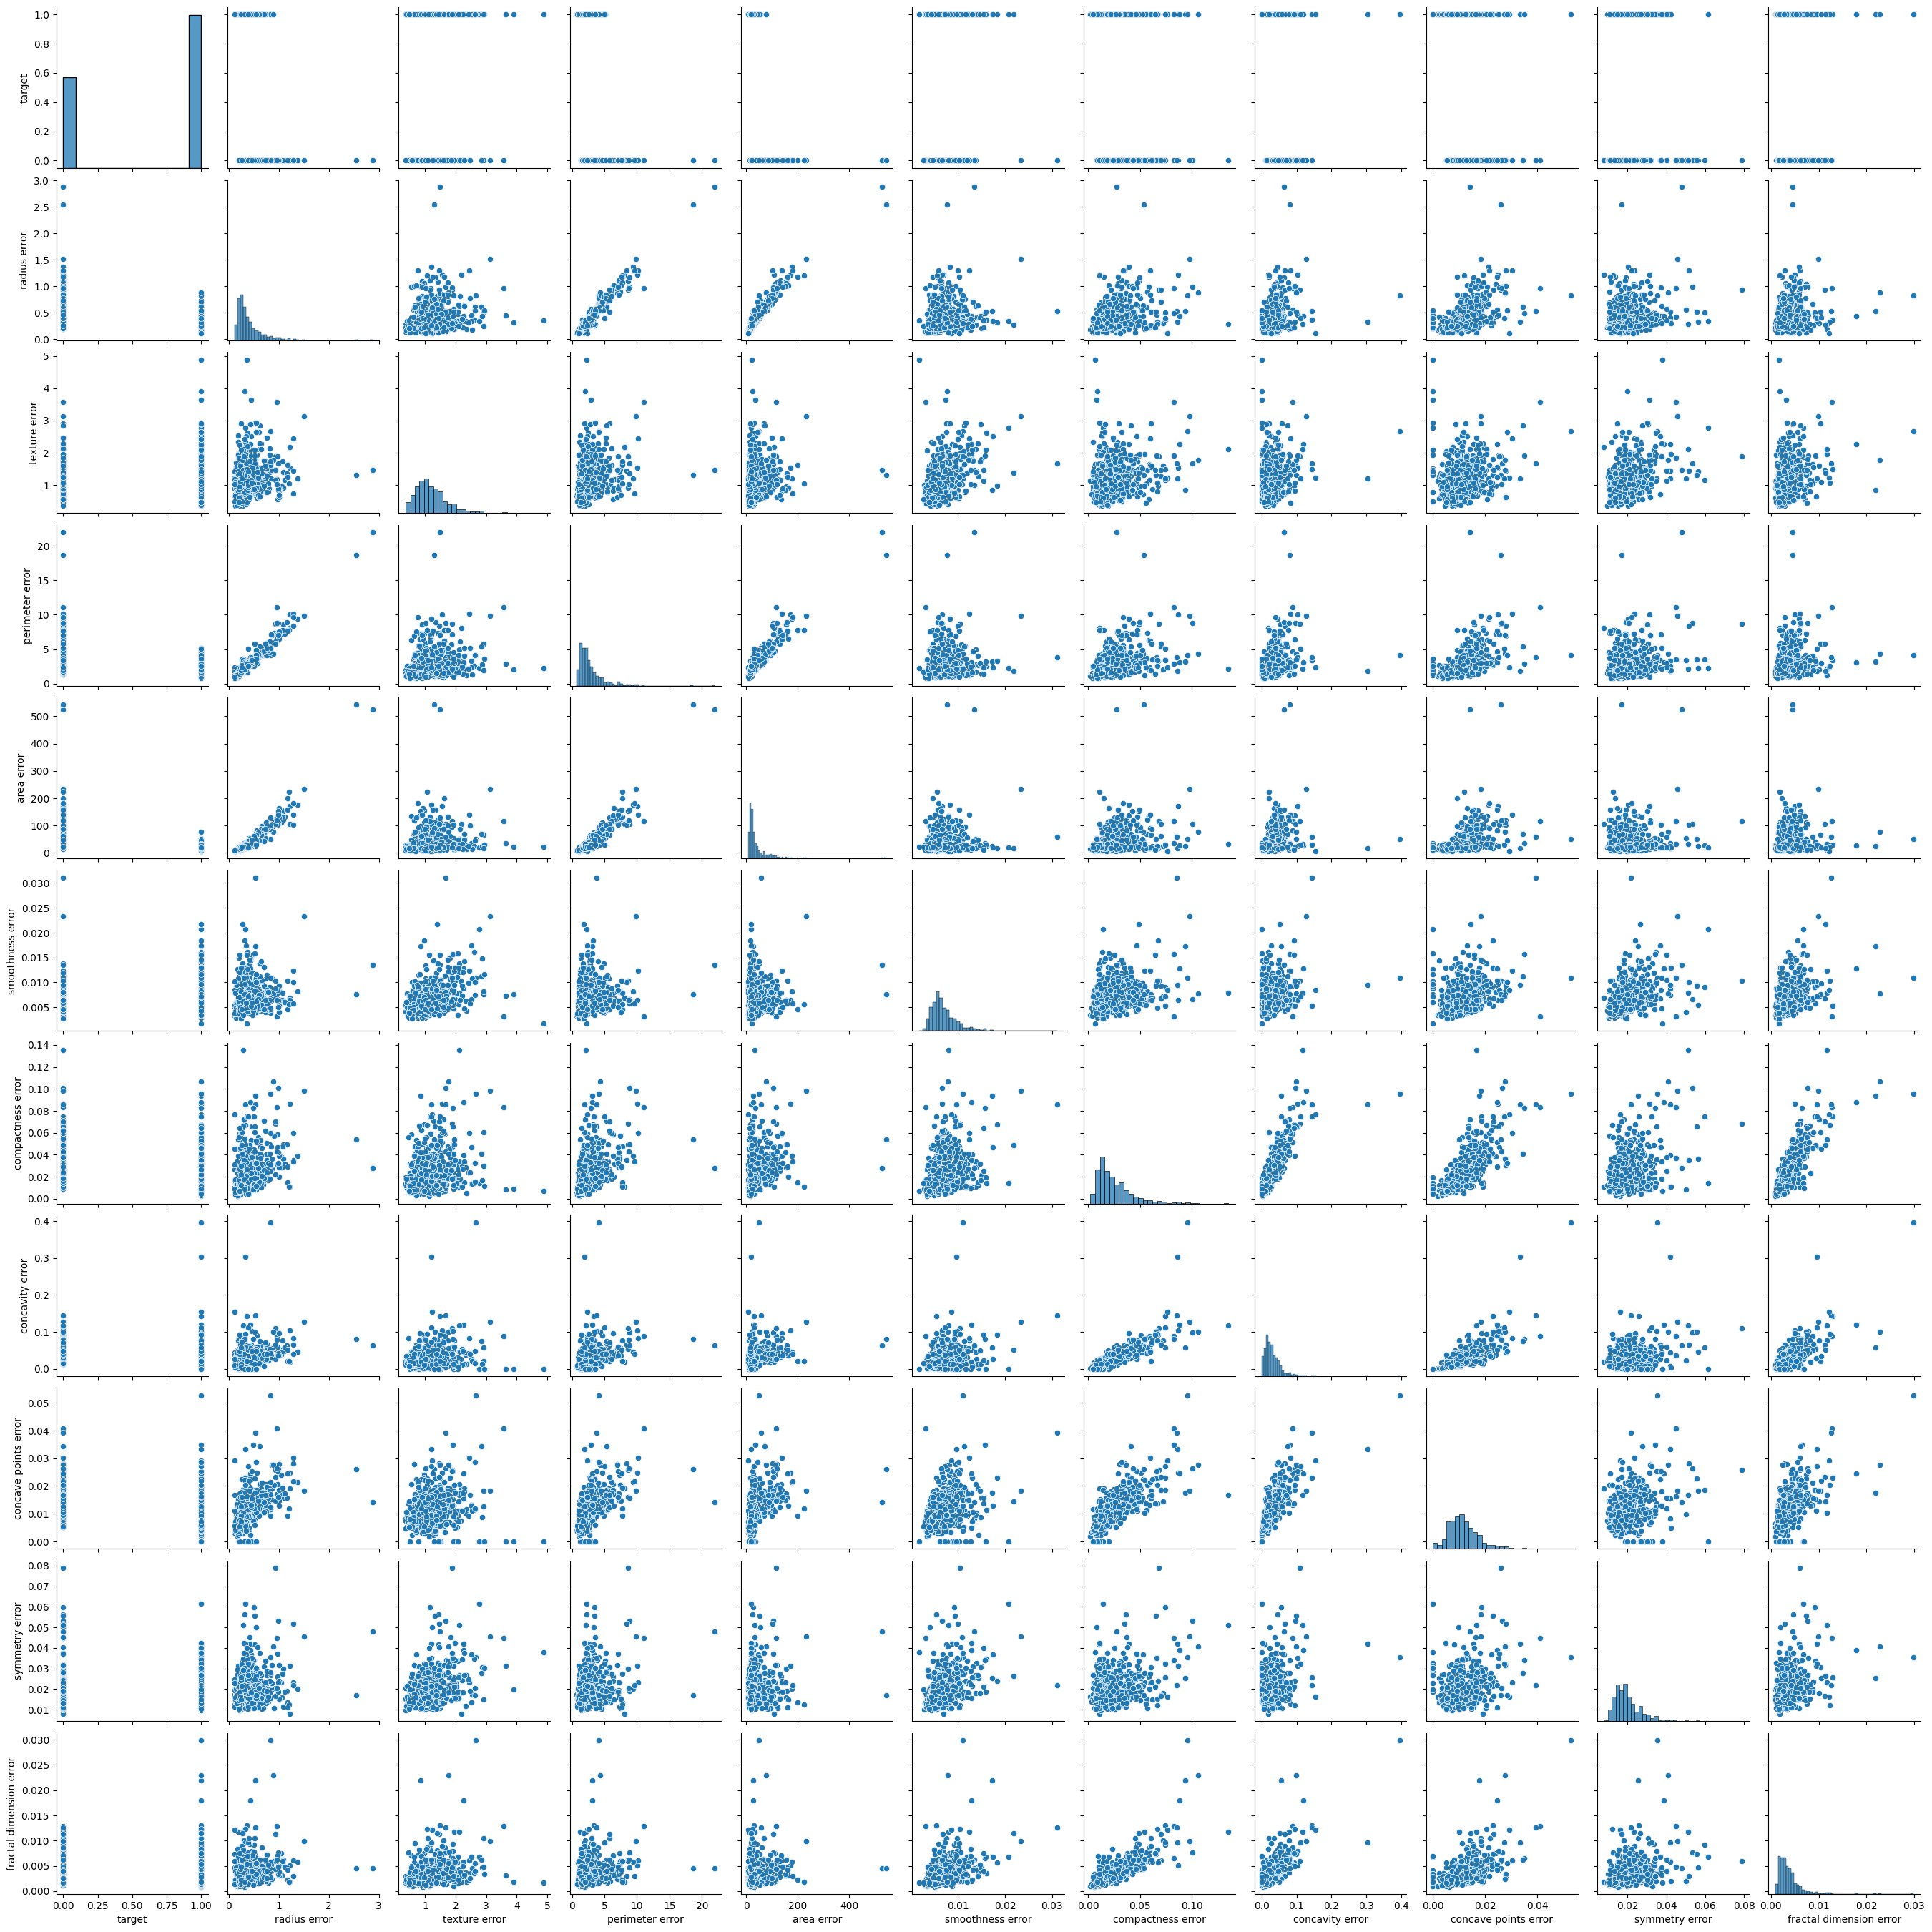

In [43]:
sns.pairplot(df[['target'] + list(df.columns[10:20])])

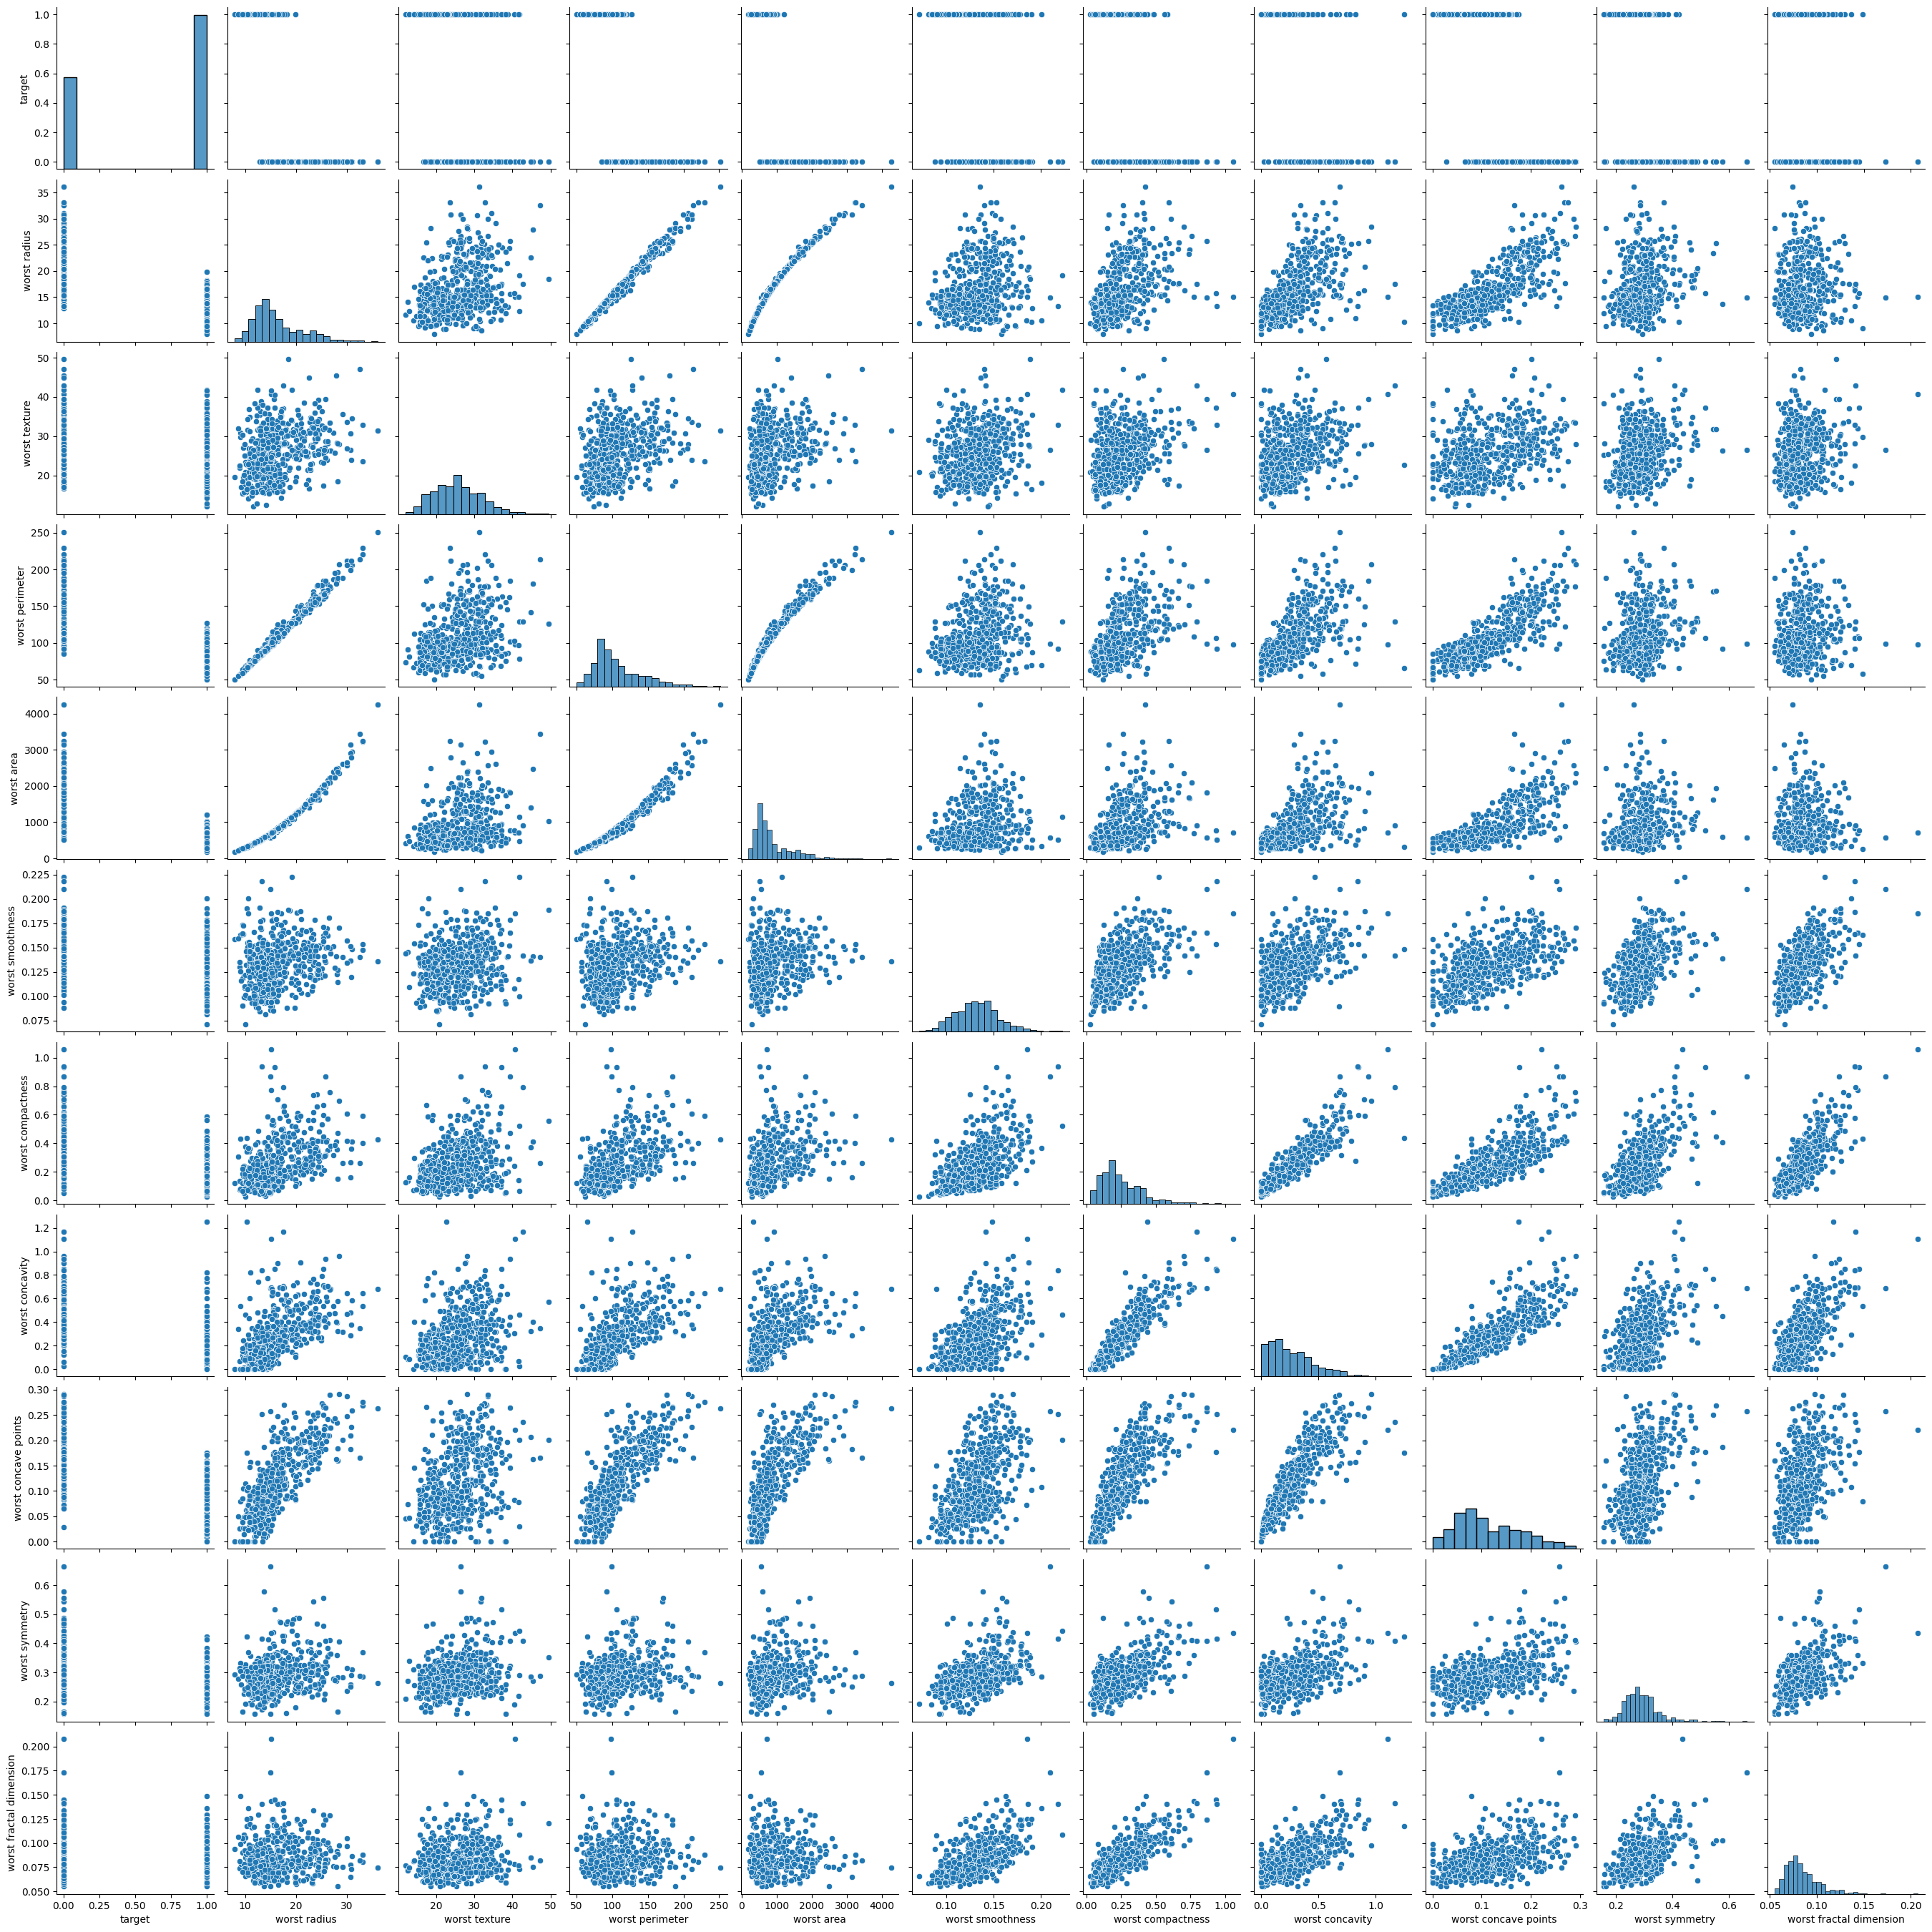

In [44]:
sns.pairplot(df[['target'] + list(df.columns[20:30])])

In [45]:
df.columns

Index(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error', 'fractal dimension error',
       'worst radius', 'worst texture', 'worst perimeter', 'worst area',
       'worst smoothness', 'worst compactness', 'worst concavity',
       'worst concave points', 'worst symmetry', 'worst fractal dimension',
       'target'],
      dtype='object')

target 컬럼과 선형관계가 있어 보이는 컬럼들만 추출하여 학습을 진행하겟다.



In [46]:
cols=['mean radius', 'mean texture','mean smoothness', 'mean compactness',
      'mean concave points','worst radius','worst compactness','worst concave points',
      'target']


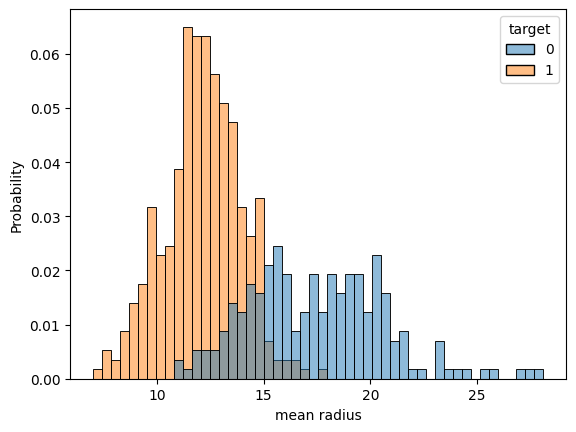

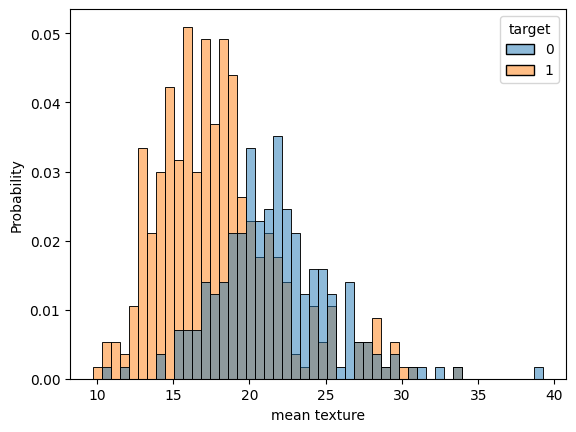

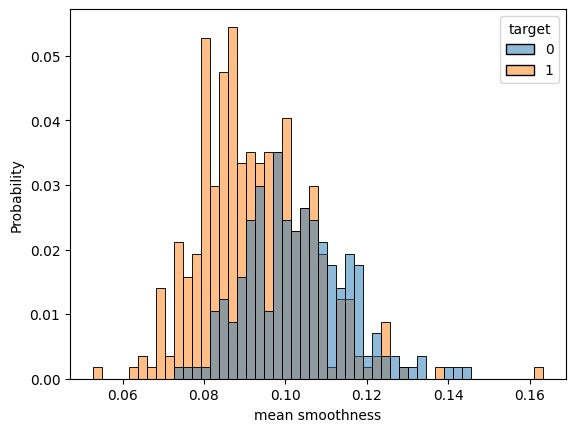

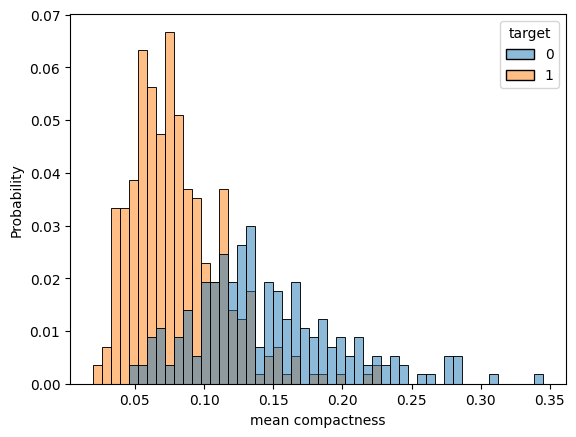

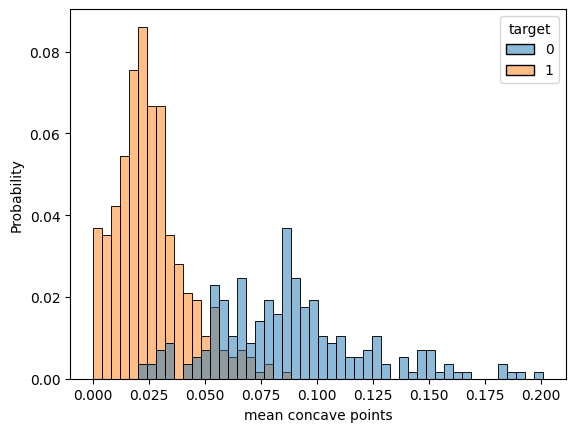

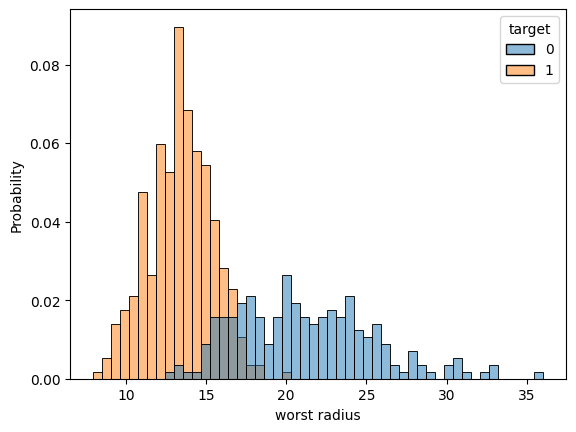

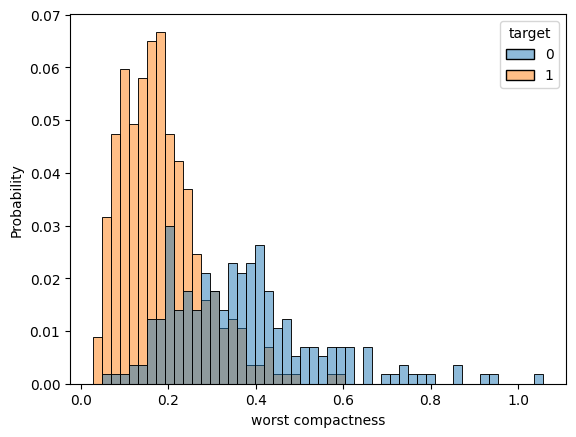

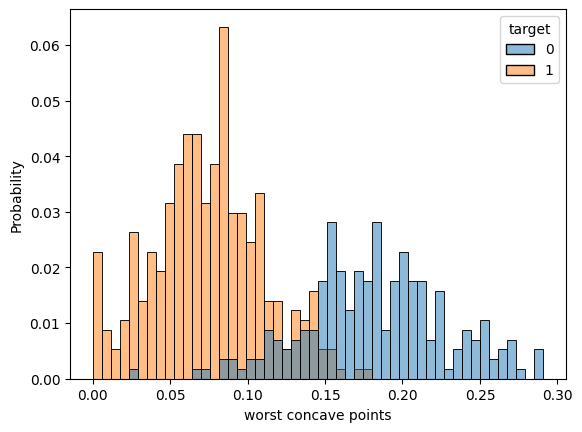

In [47]:
for c in cols[:-1]:
  sns.histplot(df,x=c,hue=cols[-1],bins=50,stat='probability')
  plt.show()

In [48]:
#텐서로 변경
data=torch.from_numpy(df[cols].values).float()

In [49]:
X=data[:,:-1]
y=data[:,-1:]
print(X.shape,y.shape)

torch.Size([569, 8]) torch.Size([569, 1])


In [57]:
X

tensor([[17.9900, 10.3800,  0.1184,  ..., 25.3800,  0.6656,  0.2654],
        [20.5700, 17.7700,  0.0847,  ..., 24.9900,  0.1866,  0.1860],
        [19.6900, 21.2500,  0.1096,  ..., 23.5700,  0.4245,  0.2430],
        ...,
        [16.6000, 28.0800,  0.0846,  ..., 18.9800,  0.3094,  0.1418],
        [20.6000, 29.3300,  0.1178,  ..., 25.7400,  0.8681,  0.2650],
        [ 7.7600, 24.5400,  0.0526,  ...,  9.4560,  0.0644,  0.0000]])

In [58]:
y

tensor([[0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [1.],
        [1.],
        [1.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [1.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [1.],
        [0.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [0.],
        [0.],
        [1.],
        [0.],
        [0.],
        [1.],
        [1.],
        [1.],
        [1.],
        [0.],
        [1.],
        [0.],
        [0.],
        [1.],
        [1.],
        [1.],
        [1.],
        [0.],
      

선형 회귀에서는 선현 계층 하나만 필요했던 것과 달리 이번에는 시그모이드 함수도 모델에 포함되어야 합니다.

In [51]:
n_epochs=200000
learning_rate=1e-3
print_interval=10000

In [52]:
class MyModel(nn.Module):
  def __init__(self,input_dim,output_dim):
    self.input_dim=input_dim
    self.output_dim=output_dim

    super().__init__()

    self.linear=nn.Linear(input_dim,output_dim)
    self.act=nn.Sigmoid()

  def forward(self,x):
    # |x|=(batch_size,input_size)
    y=self.act(self.linear(x))
    #|y|=(batch_size,output_size)

    return y

In [53]:
model=MyModel(input_dim=X.size(-1),
              output_dim=y.size(-1))

# Define BCELoss instead of MSELoss
crit=nn.BCELoss()

optimizer=optim.SGD(model.parameters(),
                    lr=learning_rate)

In [54]:
for i in tqdm(range(n_epochs)):
  y_hat=model(X)
  loss=crit(y_hat,y)

  optimizer.zero_grad()
  loss.backward()

  optimizer.step()

  if (i+1) % print_interval == 0:
    print('Epoch %d: loss=%.4e' %(i+1,loss))


  5%|▌         | 10219/200000 [00:05<01:54, 1652.02it/s]

Epoch 10000: loss=4.1315e-01


 10%|█         | 20426/200000 [00:10<01:23, 2146.17it/s]

Epoch 20000: loss=3.7222e-01


 15%|█▌        | 30358/200000 [00:15<01:23, 2020.93it/s]

Epoch 30000: loss=3.4982e-01


... (30 outputs left out)

 95%|█████████▌| 190193/200000 [01:38<00:06, 1564.52it/s]

Epoch 190000: loss=2.3373e-01


100%|██████████| 200000/200000 [01:43<00:00, 1924.15it/s]

Epoch 200000: loss=2.2987e-01


정확도 평가

In [55]:
correct_cnt=(y==(y_hat > .5)).sum()
total_cnt=float(y.size(0))

print('Accuracy: %.4f' %(correct_cnt/total_cnt))

Accuracy: 0.9192


이번 학습에서는 0.9192의 정확도가 나오는 것을 볼 수 있습니다.

<Axes: xlabel='y_hat', ylabel='Probability'>

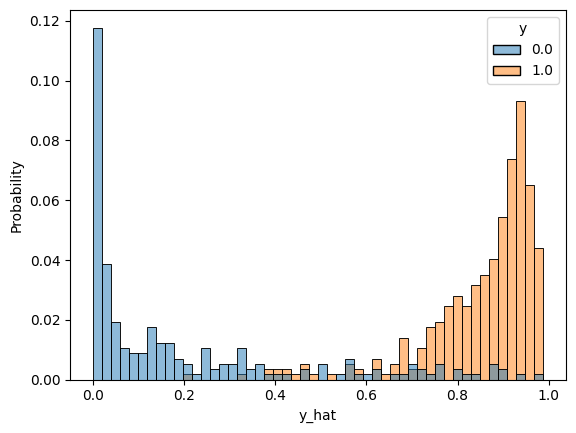

In [60]:
# 결괏값의 분포도
df=pd.DataFrame(torch.cat([y,y_hat],dim=1).detach().numpy(),
                columns=['y','y_hat'])

sns.histplot(df,x='y_hat',hue='y',bins=50,stat='probability')

만약 각 클래스별 분포가 양 극단으로 완벽하게 치우쳐져 있다면 모델이 매우 예측을 잘하고 있다고 판단할 수 있습니다.

현재 그 정도는 아니지만 대부분의 값이 양쪽에 치우쳐져 있고 일부 샘플들이 중간에 뒤엉켜 혼재하고 있음을 확인할 수 있습니다.